# 影像分類 with Vision Transformer (ViT)
## 教學目標
- 本教學著重於影像分類任務，使用 [MedMNIST 資料集](https://medmnist.com/)。
- 這份教學的目標是介紹如何以 PyTorch 和 [Transformers](https://github.com/huggingface/transformers) 實作 ViT。

In [2]:
# 0. 檢查是否使用 GPU

import torch
torch.cuda.is_available()

True

In [3]:
# 1. 安裝 MedMNIST

!pip install medmnist

### Hugging Face Auto Classes

Hugging Face `transformers` 提供了 **Auto Classes**，讓我們不需要手動指定模型的架構，就能快速載入不同的預訓練模型（Pre-trained Models）。

Auto Classes 會根據模型的設定檔（Configuration），**自動選擇對應的模型架構**。

常見的 Auto Classes 包括：
- `AutoModel`：載入模型的基礎架構（不包含特定任務的預測層）。
- `AutoModelForImageClassification`：載入用於**影像分類**的模型。
- `AutoModelForSequenceClassification`：載入用於**文字分類**的模型。
- `AutoModelForCausalLM`：載入用於**文字生成**的模型。
- `AutoImageProcessor`：載入影像模型對應的前處理設定。

**範例：載入影像分類模型**

```python
from transformers import AutoModelForImageClassification

model = AutoModelForImageClassification.from_pretrained(
    "google/vit-base-patch16-224"
)
```

在這個例子中：
1. `from_pretrained()` 會下載並載入預訓練模型（包含模型權重）。
2. Hugging Face 會自動辨識模型使用的是 **Vision Transformer (ViT)** 架構。
3. `AutoModelForImageClassification` 會載入包含影像分類層（Classification Head）的模型。

**重點：** Auto Classes 讓我們可以使用相同的程式碼介面，輕鬆切換不同的模型架構，而不必重新撰寫模型載入程式。

參考資料：[Hugging Face — Auto Classes](https://huggingface.co/docs/transformers/model_doc/auto)

In [4]:
# 2. 載入套件

from tqdm import tqdm # progress bar
# PyTorch 系列
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from torchvision.transforms import Normalize

from medmnist import PneumoniaMNIST
from transformers import AutoModelForImageClassification
from transformers import AutoImageProcessor
from transformers import ViTModel
from utils import do_test

## 超參數

In [5]:
# 3. 超參數

BATCH_SIZE = 32
EPOCHS = 3
LEARNING_RATE = 1e-4
IMAGE_SIZE = 128
PATCH_SIZE = 16
MODEL_NAME = "google/vit-base-patch16-224" # or google/vit-base-patch16-224-in21k

MODEL_TYPE = "custom"
assert MODEL_TYPE in ["HF", "custom"], "IMPLEMENTATION must be either 'HF' or 'custom'"

## 資料集

In [6]:
# 4.1 載入影像測試

tmp = PneumoniaMNIST(split="test", download=True)
print(tmp)

Dataset PneumoniaMNIST of size 28 (pneumoniamnist)
    Number of datapoints: 624
    Root location: /root/.medmnist
    Split: test
    Task: binary-class
    Number of channels: 1
    Meaning of labels: {'0': 'normal', '1': 'pneumonia'}
    Number of samples: {'train': 4708, 'val': 524, 'test': 624}
    Description: The PneumoniaMNIST is based on a prior dataset of 5,856 pediatric chest X-Ray images. The task is binary-class classification of pneumonia against normal. We split the source training set with a ratio of 9:1 into training and validation set and use its source validation set as the test set. The source images are gray-scale, and their sizes are (384−2,916)×(127−2,713). We center-crop the images and resize them into 1×28×28.
    License: CC BY 4.0


In [7]:
# 4.2 影像資料前處理準備

image_processor = AutoImageProcessor.from_pretrained(MODEL_NAME, do_rescale=False)
normalize = Normalize(
    mean=[image_processor.image_mean[0]],
    std=[image_processor.image_std[0]],
)
# Data Transform
transform = transforms.Compose(
    [
        transforms.Resize((image_processor.size["height"], image_processor.size["width"])),
        transforms.ToTensor(),
        normalize, # 可以改成你喜歡的
    ]
)

In [8]:
image_processor.image_mean[0]

0.5

In [9]:
# 5. Load PneumoniaMNIST
train_raw = PneumoniaMNIST(split="train", download=True, transform=transform)
test_raw = PneumoniaMNIST(split="test", download=True, transform=transform)
train_data, val_data = torch.utils.data.random_split(train_raw, [0.8, 0.2])

In [10]:
print(type(tmp))
tmp[1][0]

<class 'medmnist.dataset.PneumoniaMNIST'>


In [11]:
# 6. 創建 DataLoader
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_raw, batch_size=BATCH_SIZE, shuffle=False)

## 模型架構

In [12]:
# 7. 模型設置 (Custom)

class CustomViTClassifier(torch.nn.Module):
    def __init__(self, vit_model, num_labels=2):
        super().__init__()
        self.vit = vit_model
        self.config = self.vit.config
        self.classifier = torch.nn.Linear(self.vit.config.hidden_size, num_labels)

    def forward(self, pixel_values):
        # 只接受 pixel_values 參數，不接收 labels，Loss 由額外 Training Loop 計算
        # pixel_values 的 shape 是 (batch_size, channels, height, width)
        outputs = self.vit(pixel_values=pixel_values)
        logits = self.classifier(outputs.pooler_output)
        return logits

In [13]:
# 8. 模型設置 (HF)

def load_HF_model(model_name, num_labels=2):
    model = AutoModelForImageClassification.from_pretrained(
        model_name,
        num_labels=num_labels,  # PneumoniaMNIST is a binary classification
        ignore_mismatched_sizes=True, # https://github.com/huggingface/transformers/issues/13127
        problem_type="single_label_classification"  # 指定問題類型為單標籤分類
    )
    return model

In [14]:
# 9. 載入 ViT 模型

if MODEL_TYPE == "HF":
    # Load ViT Model
    model = load_HF_model(MODEL_NAME, num_labels=2)
elif MODEL_TYPE == "custom":
    base_model = ViTModel.from_pretrained(MODEL_NAME)
    # 如果是用 `ViTForImageClassification`，# 7 pooler_output 那邊會錯
    model = CustomViTClassifier(base_model, num_labels=2)

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## 觀察位置編碼

In [15]:
# 10. 印出位置編碼維度

pos_embed = base_model.embeddings.position_embeddings
print(pos_embed.shape)

torch.Size([1, 197, 768])


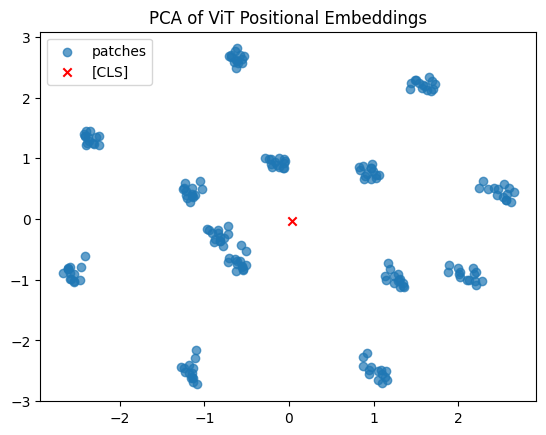

In [16]:
# 11. 畫出二維度的位置編碼

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# 去掉 batch 維度
pos_embed_np = pos_embed[0].detach().cpu().numpy()  # shape: (197, 768)

# 用 PCA 將 768 維降到 2 維
pca = PCA(n_components=2)
reduced = pca.fit_transform(pos_embed_np)

# 繪圖：不同顏色標示 CLS token vs patches
# 1: 代表排除 Index 0 的 [CLS] token
# 只取第0個 Index 代表接著點出 [CLS] token 的 embedding
plt.scatter(reduced[1:, 0], reduced[1:, 1], label='patches', alpha=0.7)
plt.scatter(reduced[0, 0], reduced[0, 1], color='red', label='[CLS]', marker='x')
plt.legend()
plt.title('PCA of ViT Positional Embeddings')
plt.show()

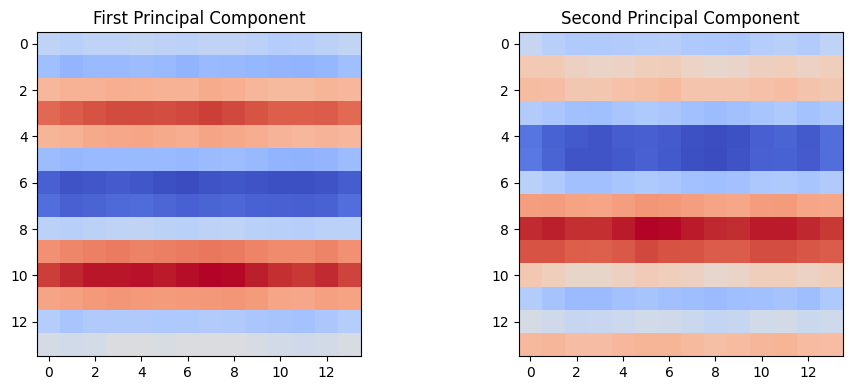

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# 排除 [CLS] Token，還原成 14 × 14 Patch Grid
pc1 = reduced[1:, 0].reshape(14, 14)
pc2 = reduced[1:, 1].reshape(14, 14)

axes[0].imshow(pc1, cmap="coolwarm")
axes[0].set_title("First Principal Component")

axes[1].imshow(pc2, cmap="coolwarm")
axes[1].set_title("Second Principal Component")

plt.tight_layout()
plt.show()

In [17]:
# 12. 訓練前準備

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
loss_fn = torch.nn.CrossEntropyLoss()

# Training Loop
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

CustomViTClassifier(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0-11): 12 x ViTLayer(
        (attention): ViTAttention(
          (q_proj): Linear(in_features=768, out_features=768, bias=True)
          (k_proj): Linear(in_features=768, out_features=768, bias=True)
          (v_proj): Linear(in_features=768, out_features=768, bias=True)
          (o_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (layernorm_before): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (layernorm_after): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (mlp): ViTMLP(
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=768, out_features=3072, bias=True)
          (fc2): Linear(in_fe

In [18]:
# 13. PyTorch training loop

for epoch in range(EPOCHS):
    pbar = tqdm(train_loader)
    pbar.set_description(f"Training epoch [{epoch+1}/{EPOCHS}]")
    model.train()
    for pixel_values, labels in pbar:
        # `pixel_values` 的維度：(batch_size, num_channels, height, width)
        pixel_values = pixel_values.repeat(1, 3, 1, 1)  # 複製通道 3 次
        pixel_values = pixel_values.to(device)
        labels = labels.squeeze().to(device)

        optimizer.zero_grad()

        if MODEL_TYPE == "HF":
            outputs = model(pixel_values=pixel_values, labels=labels).logits
        elif MODEL_TYPE == "custom":
            outputs = model(pixel_values=pixel_values)

        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()
        pbar.set_postfix(loss = loss.item())

    print(f'Epoch {epoch + 1}/{EPOCHS}, Loss: {loss.item():.4f}')

    do_test(val_loader, model, MODEL_TYPE, loss_fn, device, EPOCHS, epoch)

Training epoch [1/3]: 100%|██████████| 118/118 [00:28<00:00,  4.09it/s, loss=0.0576]


Epoch 1/3, Loss: 0.0576


validation epoch [1/3]: 100%|██████████| 30/30 [00:02<00:00, 10.91it/s]


Accuracy: 0.9639 
F1 Score: 0.9551


Training epoch [2/3]: 100%|██████████| 118/118 [00:28<00:00,  4.17it/s, loss=0.00344]


Epoch 2/3, Loss: 0.0034


... (2 outputs left out)

Training epoch [3/3]: 100%|██████████| 118/118 [00:28<00:00,  4.15it/s, loss=0.0262]


Epoch 3/3, Loss: 0.0262


validation epoch [3/3]: 100%|██████████| 30/30 [00:02<00:00, 10.83it/s]

Accuracy: 0.9724 
F1 Score: 0.9649
